<a href="https://colab.research.google.com/github/abhiii04-25/Deep-Learning/blob/main/Digit_Classification_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder , StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import Perceptron    # Used for simple linear classification tasks.

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.models import Sequential     # Sequential lets you build a neural network layer-by-layer in Keras.

from tensorflow.keras.layers import Dense     #Dense makes the final predictions
from tensorflow.keras.layers import Conv2D     # Conv2D extracts features
from tensorflow.keras.layers import Flatten    # Flatten reshapes them

from tensorflow.keras.layers import MaxPooling2D     # MaxPooling2D reduces size
from tensorflow.keras.layers import Dropout          # Dropout prevents overfitting

from tensorflow.keras.utils import to_categorical     # converts numeric class labels into one-hot encoded format for training classification models


In [4]:
df=pd.read_csv("train.csv")
df_test=pd.read_csv("test.csv")

In [5]:
df.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
df.shape

(6304, 785)

In [7]:
df.columns

Index(['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5',
       'pixel6', 'pixel7', 'pixel8',
       ...
       'pixel774', 'pixel775', 'pixel776', 'pixel777', 'pixel778', 'pixel779',
       'pixel780', 'pixel781', 'pixel782', 'pixel783'],
      dtype='object', length=785)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6304 entries, 0 to 6303
Columns: 785 entries, label to pixel783
dtypes: float64(114), int64(671)
memory usage: 37.8 MB


In [9]:
df.isnull().sum()

,0
label,0
pixel0,0
pixel1,0
pixel2,0
pixel3,0
...,...
pixel779,1
pixel780,1
pixel781,1
pixel782,1


In [10]:
print("Training columns:", df.columns.tolist())
print("Testing columns:", df_test.columns.tolist())

Training columns: ['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6', 'pixel7', 'pixel8', 'pixel9', 'pixel10', 'pixel11', 'pixel12', 'pixel13', 'pixel14', 'pixel15', 'pixel16', 'pixel17', 'pixel18', 'pixel19', 'pixel20', 'pixel21', 'pixel22', 'pixel23', 'pixel24', 'pixel25', 'pixel26', 'pixel27', 'pixel28', 'pixel29', 'pixel30', 'pixel31', 'pixel32', 'pixel33', 'pixel34', 'pixel35', 'pixel36', 'pixel37', 'pixel38', 'pixel39', 'pixel40', 'pixel41', 'pixel42', 'pixel43', 'pixel44', 'pixel45', 'pixel46', 'pixel47', 'pixel48', 'pixel49', 'pixel50', 'pixel51', 'pixel52', 'pixel53', 'pixel54', 'pixel55', 'pixel56', 'pixel57', 'pixel58', 'pixel59', 'pixel60', 'pixel61', 'pixel62', 'pixel63', 'pixel64', 'pixel65', 'pixel66', 'pixel67', 'pixel68', 'pixel69', 'pixel70', 'pixel71', 'pixel72', 'pixel73', 'pixel74', 'pixel75', 'pixel76', 'pixel77', 'pixel78', 'pixel79', 'pixel80', 'pixel81', 'pixel82', 'pixel83', 'pixel84', 'pixel85', 'pixel86', 'pixel87', 'pixel88', 'pi

In [11]:
X_train = df.drop("label", axis=1).values
y_train = df["label"].values

X_test = df_test.values

In [12]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)

X_train: (6304, 784)
y_train: (6304,)
X_test: (6314, 784)


In [13]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [14]:
X_train_img = X_train.reshape(-1, 28, 28)
X_test_img = X_test.reshape(-1, 28, 28)


In [15]:
from tensorflow.keras.utils import to_categorical

y_train_cat = to_categorical(y_train, 10)

print(y_train_cat.shape)

(6304, 10)


In [16]:
perceptron = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(10, activation="softmax")
])


In [22]:
import numpy as np

print("X_train_img shape:", X_train_img.shape)
print("X_train_img min:", np.nanmin(X_train_img))
print("X_train_img max:", np.nanmax(X_train_img))
print("NaN in X_train_img:", np.isnan(X_train_img).any())
print("Infinite in X_train_img:", np.isinf(X_train_img).any())

print("NaN in y_train_cat:", np.isnan(y_train_cat).any())
print("Infinite in y_train_cat:", np.isinf(y_train_cat).any())
print("Unique labels:", np.unique(y_train))

X_train_img shape: (6304, 28, 28)
X_train_img min: 0.0
X_train_img max: 1.0
NaN in X_train_img: True
Infinite in X_train_img: False
NaN in y_train_cat: False
Infinite in y_train_cat: False
Unique labels: [0 1 2 3 4 5 6 7 8 9]


In [23]:
import numpy as np

print("NaN values in X_train_img:", np.isnan(X_train_img).sum())
print("Total pixels:", X_train_img.size)
print("Images containing NaN:",
      np.isnan(X_train_img).any(axis=(1, 2)).sum())

NaN values in X_train_img: 114
Total pixels: 4942336
Images containing NaN: 1


In [24]:
X_train_img = np.nan_to_num(
    X_train_img,
    nan=0.0,
    posinf=1.0,
    neginf=0.0
)

In [25]:
X_test_img = np.nan_to_num(
    X_test_img,
    nan=0.0,
    posinf=1.0,
    neginf=0.0
)

In [26]:
print("Training NaNs:", np.isnan(X_train_img).sum())
print("Test NaNs:", np.isnan(X_test_img).sum())

Training NaNs: 0
Test NaNs: 0


In [27]:
perceptron.compile(optimizer="adam", loss="categorical_crossentropy",
                   metrics=["accuracy"])

In [29]:
history_percp = perceptron.fit(
    X_train_img,
    y_train_cat,
    epochs=5,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/5
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.0988 - loss: nan - val_accuracy: 0.1015 - val_loss: nan
Epoch 2/5
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.0988 - loss: nan - val_accuracy: 0.1015 - val_loss: nan
Epoch 3/5
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.0988 - loss: nan - val_accuracy: 0.1015 - val_loss: nan
Epoch 4/5
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.0988 - loss: nan - val_accuracy: 0.1015 - val_loss: nan
Epoch 5/5
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.0988 - loss: nan - val_accuracy: 0.1015 - val_loss: nan


In [30]:
import numpy as np
import tensorflow as tf

print("1. Training images finite:",
      np.isfinite(X_train_img).all())

print("2. Labels finite:",
      np.isfinite(y_train_cat).all())

print("3. Model output shape:",
      perceptron.output_shape)

print("4. Model weights finite:",
      all(np.isfinite(w).all() for w in perceptron.get_weights()))

pred = perceptron(X_train_img[:5], training=False).numpy()

print("5. Predictions finite:",
      np.isfinite(pred).all())

print("6. First predictions:")
print(pred[:2])

print("7. Model summary:")
perceptron.summary()

1. Training images finite: True
2. Labels finite: True
3. Model output shape: (None, 10)
4. Model weights finite: False
5. Predictions finite: False
6. First predictions:
[[nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan]]
7. Model summary:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,552 (92.00 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 15,702 (61.34 KB)

In [31]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense

perceptron = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(10, activation="softmax")
])

perceptron.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [32]:
import numpy as np

print(
    "Weights finite:",
    all(np.isfinite(w).all() for w in perceptron.get_weights())
)

Weights finite: True


In [33]:
history_percp = perceptron.fit(
    X_train_img,
    y_train_cat,
    epochs=5,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/5
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7059 - loss: 1.2135 - val_accuracy: 0.8382 - val_loss: 0.7356
Epoch 2/5
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8620 - loss: 0.5933 - val_accuracy: 0.8684 - val_loss: 0.5337
Epoch 3/5
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8866 - loss: 0.4676 - val_accuracy: 0.8755 - val_loss: 0.4616
Epoch 4/5
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8979 - loss: 0.4066 - val_accuracy: 0.8810 - val_loss: 0.4232
Epoch 5/5
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9056 - loss: 0.3679 - val_accuracy: 0.8795 - val_loss: 0.4033


In [34]:
# Predict digits for the test images
predictions = perceptron.predict(X_test_img)

# Convert probabilities into digit labels (0–9)
predicted_labels = np.argmax(predictions, axis=1)

print("First 10 predictions:", predicted_labels[:10])
print("Total predictions:", len(predicted_labels))

198/198 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
First 10 predictions: [2 0 9 9 3 7 0 3 0 3]
Total predictions: 6314


In [36]:
acc_percp = max(history_percp.history["val_accuracy"])
print("Best validation accuracy:", acc_percp)

Best validation accuracy: 0.8810467720031738


In [37]:

#ANN
ann = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

In [38]:
ann.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

In [41]:
history_ann = ann.fit(
    X_train_img,
    y_train_cat,
    epochs=5,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/5
158/158 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7999 - loss: 0.7126 - val_accuracy: 0.8739 - val_loss: 0.3714
Epoch 2/5
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9195 - loss: 0.2789 - val_accuracy: 0.8993 - val_loss: 0.3103
Epoch 3/5
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9407 - loss: 0.1992 - val_accuracy: 0.9183 - val_loss: 0.2461
Epoch 4/5
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9603 - loss: 0.1400 - val_accuracy: 0.9247 - val_loss: 0.2370
Epoch 5/5
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9752 - loss: 0.1052 - val_accuracy: 0.9326 - val_loss: 0.2101


In [43]:
acc_ann = max(history_ann.history["val_accuracy"])
print("Best ANN validation accuracy:", acc_ann)
print(f"Accuracy: {acc_ann * 100:.2f}%")

Best ANN validation accuracy: 0.9325931668281555
Accuracy: 93.26%


In [44]:
X_train_cnn = X_train.reshape(-1, 28, 28,1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

In [45]:
cnn = Sequential([
    Conv2D(32, kernel_size=(3,3), activation="relu", input_shape=(28,28,1)),
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(64, kernel_size=(3,3), activation="relu"),
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(10, activation="softmax")
])

In [46]:
cnn.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

In [49]:
history_cnn = cnn.fit(
    X_train_cnn,
    y_train_cat,
    epochs=5,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/5
158/158 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - accuracy: 0.7281 - loss: 0.8573 - val_accuracy: 0.9350 - val_loss: nan
Epoch 2/5
158/158 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.9221 - loss: 0.2650 - val_accuracy: 0.9508 - val_loss: nan
Epoch 3/5
158/158 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.9431 - loss: 0.1930 - val_accuracy: 0.9619 - val_loss: nan
Epoch 4/5
158/158 ━━━━━━━━━━━━━━━━━━━━ 9s 34ms/step - accuracy: 0.9552 - loss: 0.1499 - val_accuracy: 0.9627 - val_loss: nan
Epoch 5/5
158/158 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.9659 - loss: 0.1179 - val_accuracy: 0.9619 - val_loss: nan


In [50]:
acc_cnn = max(history_cnn.history["val_accuracy"])

print(f"Best CNN validation accuracy: {acc_cnn * 100:.2f}%")

Best CNN validation accuracy: 96.27%


In [51]:
def plot_training(history, title):
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(history.history['accuracy'], label="Train")
    plt.plot(history.history['val_accuracy'], label="Val")
    plt.title(f"{title} Accuracy")
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(history.history['loss'], label="Train")
    plt.plot(history.history['val_loss'], label="Val")
    plt.title(f"{title} Loss")
    plt.legend()
    plt.show()

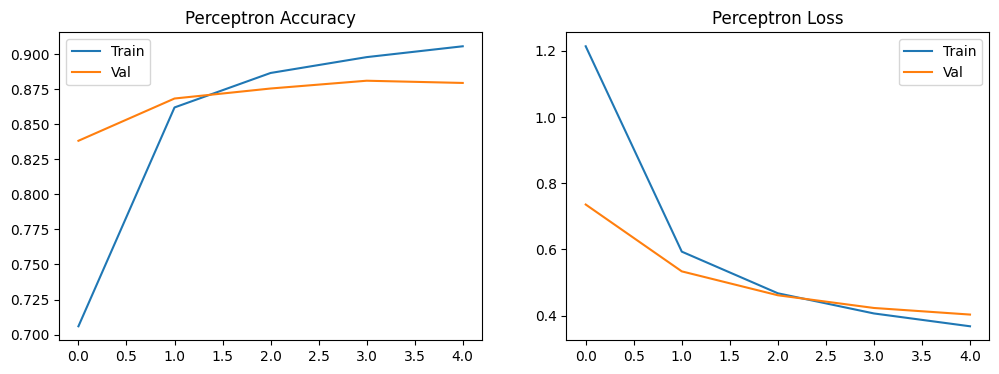

In [52]:
plot_training(history_percp, "Perceptron")

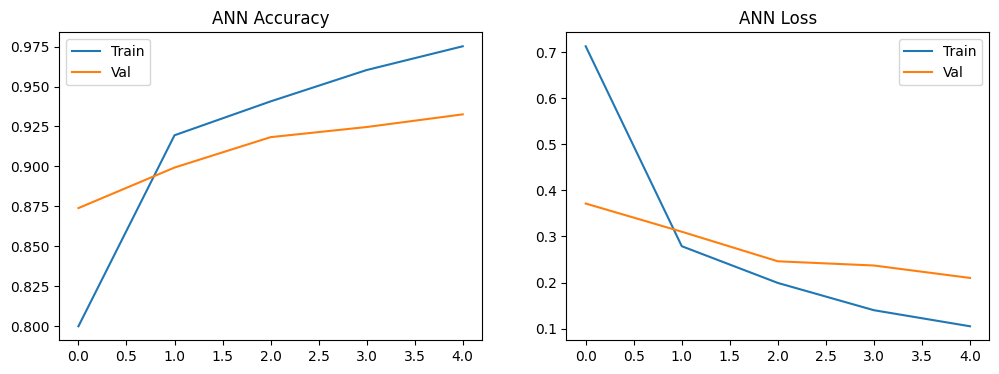

In [53]:
plot_training(history_ann, "ANN")

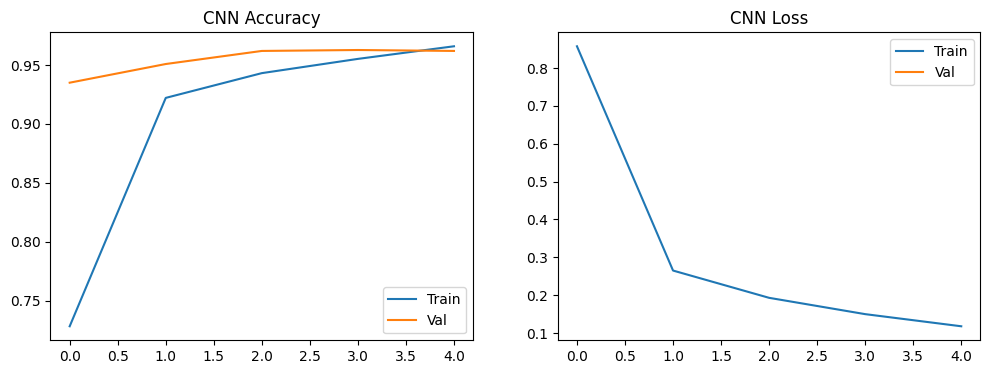

In [54]:
plot_training(history_cnn, "CNN")

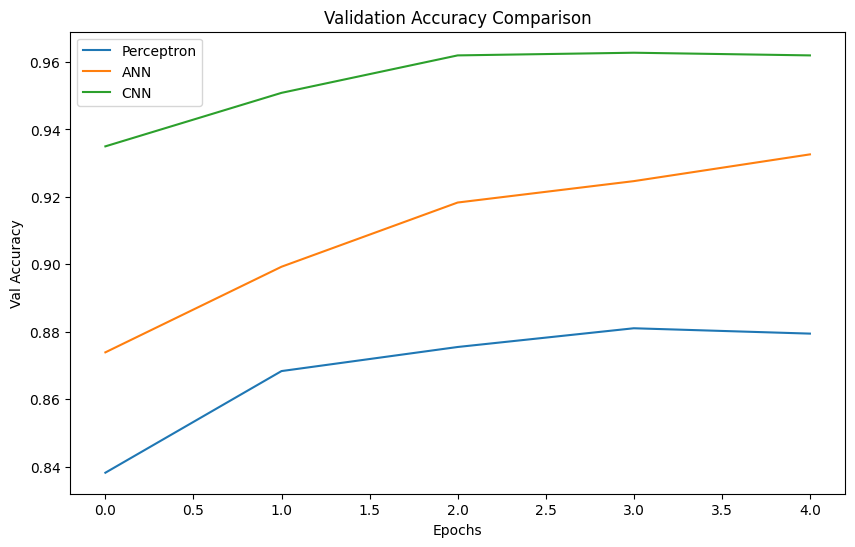

In [55]:
plt.figure(figsize=(10,6))
plt.plot(history_percp.history['val_accuracy'], label="Perceptron")
plt.plot(history_ann.history['val_accuracy'], label="ANN")
plt.plot(history_cnn.history['val_accuracy'], label="CNN")
plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Val Accuracy")
plt.legend()
plt.show()


In [56]:
def show_side_by_side(models, model_names, X, X_cnn, y_true, n=5):
    idxs = np.random.choice(len(X), n, replace=False)
    plt.figure(figsize=(15, 6))
    for i, idx in enumerate(idxs):
        plt.subplot(2, n, i+1)
        plt.imshow(X[idx].reshape(28, 28), cmap="gray")
        plt.axis("off")
        plt.title(f"True: {y_true[idx]}")
        preds = [np.argmax(model.predict(X_cnn[idx].reshape(1, 28, 28, 1) if name == "CNN" else X[idx].reshape(1, 28, 28)))
                 for model, name in zip(models, model_names)]
        plt.subplot(2, n, n+i+1)
        plt.axis("off")
        plt.title("\n".join(f"{n}: {p}" for n, p in zip(model_names, preds)))
    plt.tight_layout()
    plt.show()

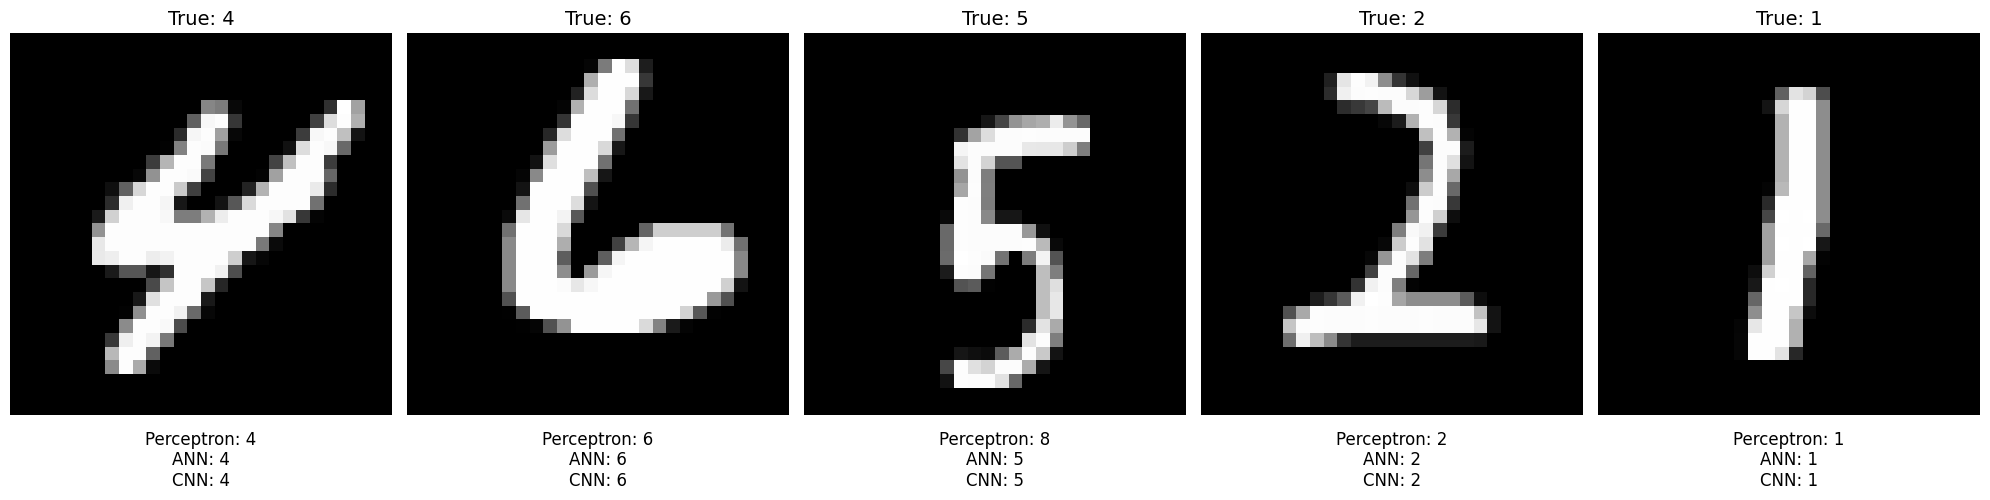

In [69]:

import numpy as np
import matplotlib.pyplot as plt

def compare_models_randomly(n=5):

    # Pick 5 random images from the labeled training dataset
    indices = np.random.choice(
        len(X_train_img), size=n, replace=False
    )

    fig, axes = plt.subplots(1, n, figsize=(4*n, 5))

    if n == 1:
        axes = [axes]

    for i, idx in enumerate(indices):

        img = X_train_img[idx:idx+1]
        img_cnn = img.reshape(-1, 28, 28, 1)

        # Predict using all three models
        p1 = np.argmax(perceptron.predict(img, verbose=0)[0])
        p2 = np.argmax(ann.predict(img, verbose=0)[0])
        p3 = np.argmax(cnn.predict(img_cnn, verbose=0)[0])

        # True digit from one-hot encoded training labels
        true_label = np.argmax(y_train_cat[idx])

        axes[i].imshow(X_train_img[idx], cmap="gray")
        axes[i].set_title(f"True: {true_label}", fontsize=14)
        axes[i].axis("off")

        axes[i].text(
            0.5, -0.04,
            f"Perceptron: {p1}\nANN: {p2}\nCNN: {p3}",
            transform=axes[i].transAxes,
            ha="center", va="top", fontsize=12
        )

    plt.tight_layout()
    plt.show()

# Run this cell again for new random images
compare_models_randomly(5)


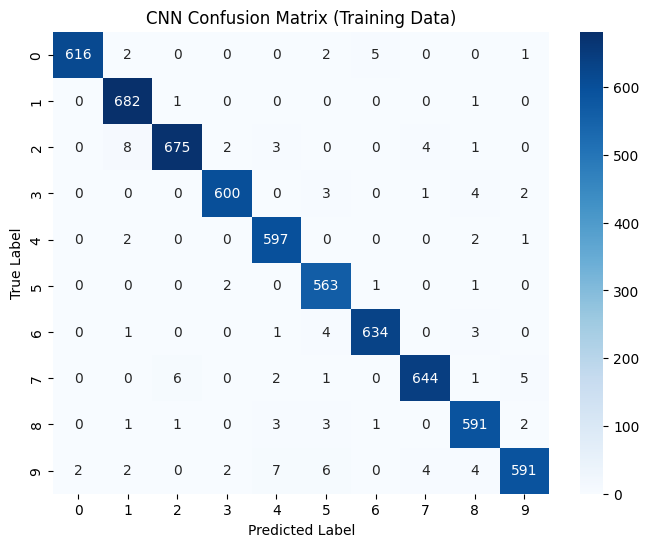

In [71]:

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Use labeled images and labels
y_true = np.argmax(y_train_cat, axis=1)

# CNN predictions on the same images
X_cnn = X_train_img.reshape(-1, 28, 28, 1)
y_pred = np.argmax(cnn.predict(X_cnn, verbose=0), axis=1)

# Create confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=range(10))

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("CNN Confusion Matrix (Training Data)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()



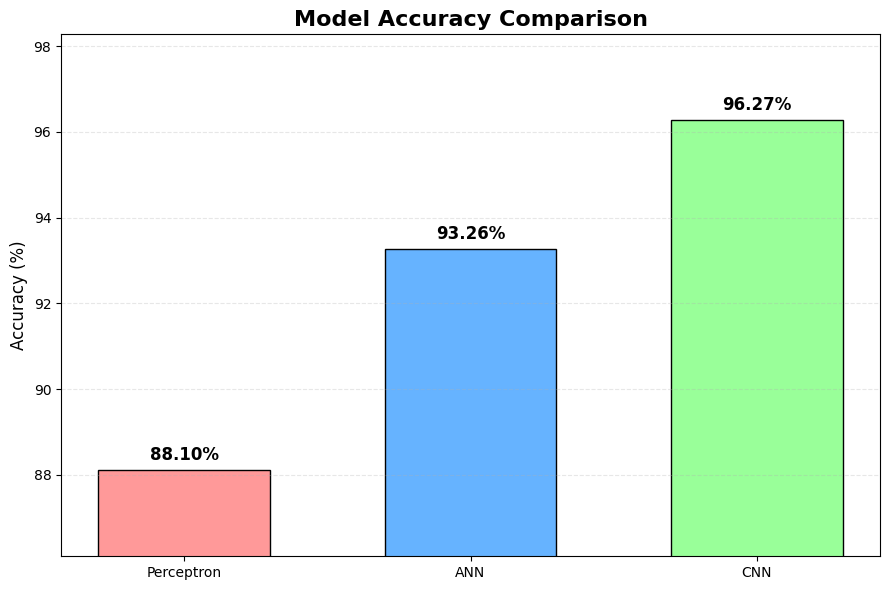

In [73]:

import matplotlib.pyplot as plt
import numpy as np

final_accs = [acc_percp * 100, acc_ann * 100, acc_cnn * 100]
models = ["Perceptron", "ANN", "CNN"]

plt.figure(figsize=(9, 6))

bars = plt.bar(
    models,
    final_accs,
    color=['#ff9999', '#66b3ff', '#99ff99'],
    edgecolor='black',
    width=0.6
)

plt.title("Model Accuracy Comparison", fontsize=16, fontweight='bold')
plt.ylabel("Accuracy (%)", fontsize=12)

# Zoom in to make small differences visible
lower = max(0, min(final_accs) - 2)
upper = min(100, max(final_accs) + 2)
plt.ylim(lower, upper)

# Display exact accuracy values
for bar, acc in zip(bars, final_accs):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        acc + 0.15,
        f"{acc:.2f}%",
        ha='center',
        va='bottom',
        fontsize=12,
        fontweight='bold'
    )

plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
from google.colab import drive
drive.mount('/content/drive')